In [ ]:

import kagglehub
anirudhchauhan_retail_store_inventory_forecasting_dataset_path = kagglehub.dataset_download('anirudhchauhan/retail-store-inventory-forecasting-dataset')

print('Data source import complete.')


100%|██████████| 1.51M/1.51M [00:00<00:00, 102MB/s]

Extracting files...
Data source import complete.


# Retail Store Inventory Forecasting

![image.png](attachment:a418d461-0f82-44e1-aea9-854749e3d165.png)

# ****This forecasting helps retailers maintain optimal inventory levels, reduce the cost of overstocking, and meet customer demands!abs****

# * Data Loading and Exploration

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from sklearn.ensemble import VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
%matplotlib inline



In [ ]:
# Load the dataset
file_path
df = pd.read_csv("/content/retail_store_inventory.csv")

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231.0,127.0,55.0,135.47,33.50,20.0,Rainy,0.0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204.0,150.0,66.0,144.04,63.01,20.0,Sunny,0.0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102.0,65.0,51.0,74.02,27.99,10.0,Sunny,1.0,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469.0,61.0,164.0,62.18,32.72,10.0,Cloudy,1.0,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166.0,14.0,135.0,9.26,73.64,0.0,Sunny,0.0,68.95,Summer


In [ ]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality'],
      dtype='object')

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49525 entries, 0 to 49524
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                49525 non-null  object 
 1   Store ID            49525 non-null  object 
 2   Product ID          49525 non-null  object 
 3   Category            49524 non-null  object 
 4   Region              49524 non-null  object 
 5   Inventory Level     49524 non-null  float64
 6   Units Sold          49524 non-null  float64
 7   Units Ordered       49524 non-null  float64
 8   Demand Forecast     49524 non-null  float64
 9   Price               49524 non-null  float64
 10  Discount            49524 non-null  float64
 11  Weather Condition   49524 non-null  object 
 12  Holiday/Promotion   49524 non-null  float64
 13  Competitor Pricing  49524 non-null  float64
 14  Seasonality         49524 non-null  object 
dtypes: float64(8), object(7)
memory usage: 5.7+ MB
None


In [ ]:
print("\nSummary Statistics for Numerical Columns:")
print(df.describe())


Summary Statistics for Numerical Columns:
       Inventory Level    Units Sold  Units Ordered  Demand Forecast  \
count     49524.000000  49524.000000   49524.000000     49524.000000   
mean        274.636742    136.389266     110.046119       141.418258   
std         129.728313    108.940073      52.334443       109.302494   
min          50.000000      0.000000      20.000000        -9.990000   
25%         163.000000     48.000000      65.000000        53.587500   
50%         274.000000    108.000000     110.000000       112.820000   
75%         387.000000    202.000000     155.000000       207.680000   
max         500.000000    496.000000     200.000000       512.360000   

              Price      Discount  Holiday/Promotion  Competitor Pricing  
count  49524.000000  49524.000000       49524.000000        49524.000000  
mean      55.335220     10.021808           0.500040           55.345722  
std       26.033471      7.077314           0.500005           26.198236  
min     

In [ ]:
#check null
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Date                  0
Store ID              0
Product ID            0
Category              1
Region                1
Inventory Level       1
Units Sold            1
Units Ordered         1
Demand Forecast       1
Price                 1
Discount              1
Weather Condition     1
Holiday/Promotion     1
Competitor Pricing    1
Seasonality           1
dtype: int64


In [ ]:
# dispay frequency count for categorical columns
categorical_columns=df.select_dtypes(include=['object']).columns
for col in categorical_columns:
    print(f"\nFrequency counts for {col}:")
    print(df[col].value_counts())
    print(f"Percentage distribution for {col}:")



Frequency counts for Date:
Date
2023-04-25    100
2023-04-24    100
2023-04-23    100
2023-04-22    100
2023-04-21    100
             ... 
2022-01-04    100
2022-01-03    100
2022-01-02    100
2022-01-01    100
2023-05-11     25
Name: count, Length: 496, dtype: int64
Percentage distribution for Date:

Frequency counts for Store ID:
Store ID
S001    9920
S002    9905
S003    9900
S004    9900
S005    9900
Name: count, dtype: int64
Percentage distribution for Store ID:

Frequency counts for Product ID:
Product ID
P0001    2477
P0002    2477
P0003    2477
P0004    2477
P0005    2476
P0006    2476
P0007    2476
P0008    2476
P0009    2476
P0010    2476
P0011    2476
P0012    2476
P0013    2476
P0014    2476
P0015    2476
P0016    2476
P0017    2476
P0018    2476
P0019    2476
P0020    2476
P000        1
Name: count, dtype: int64
Percentage distribution for Product ID:

Frequency counts for Category:
Category
Groceries      10041
Toys            9946
Clothing        9918
Furniture       9

In [ ]:
print("\nAdditional Statistics:")
print(f"Total number of stores: {df['Store ID'].nunique()}")
print(f"Total number of products: {df['Product ID'].nunique()}")
print(f"Date range: from {df['Date'].min()} to {df['Date'].max()}")


Additional Statistics:
Total number of stores: 5
Total number of products: 21
Date range: from 2022-01-01 to 2023-05-11


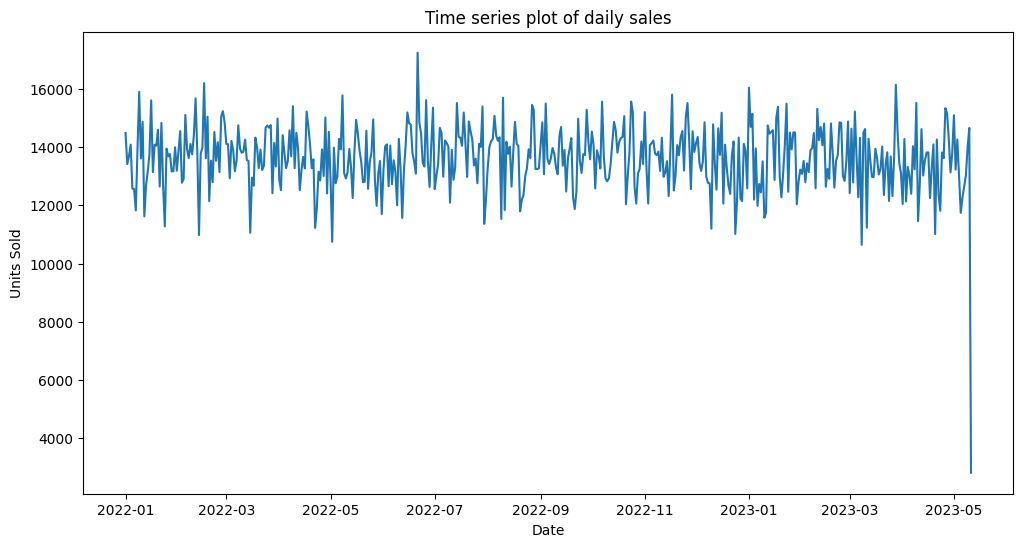

In [ ]:
# Aggregate data by date

#convert data to datetime
df['Date']= pd.to_datetime(df['Date'])
daily_sales = df.groupby('Date')['Units Sold'].sum().reset_index()

# Plot daily sales
plt.figure(figsize=(12, 6))
plt.plot(daily_sales['Date'], daily_sales['Units Sold'])
plt.title('Time series plot of daily sales')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.show()

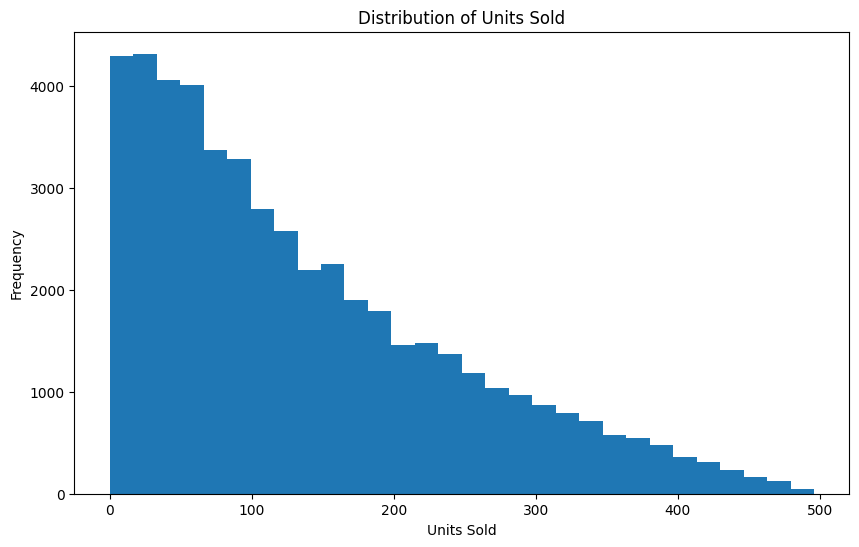

In [ ]:

plt.figure(figsize=(10, 6))
plt.hist(df['Units Sold'], bins=30)
plt.title('Distribution of Units Sold')
plt.xlabel('Units Sold')
plt.ylabel('Frequency')
plt.show()

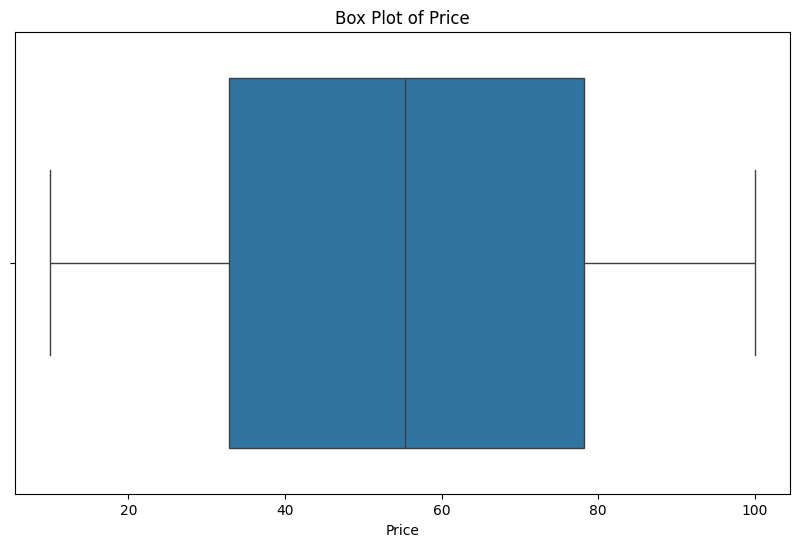

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Price'])
plt.title('Box Plot of Price')
plt.show()

# **Exploratory Data Analysis (EDA)**

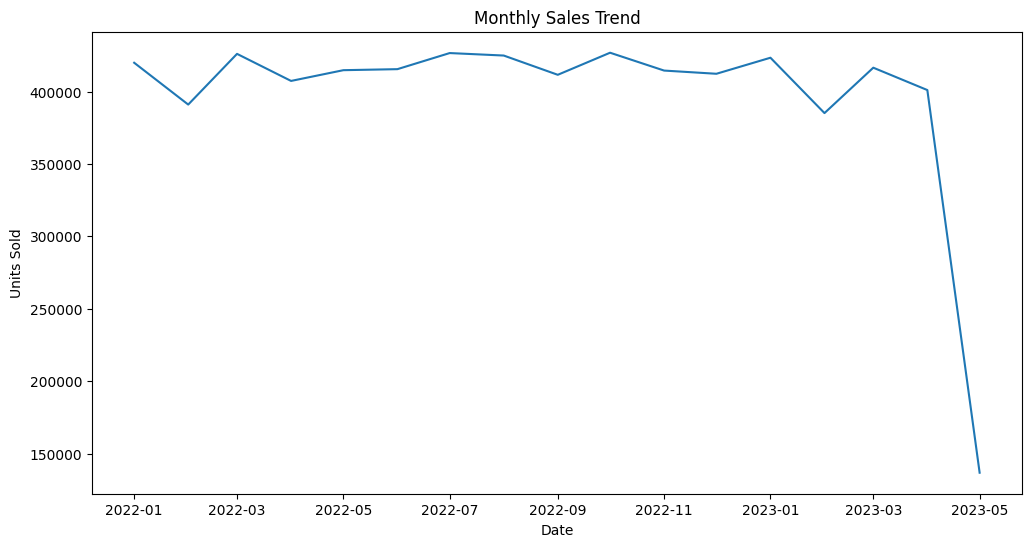

In [ ]:
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Units Sold'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Date'].dt.to_timestamp()
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales['Date'], monthly_sales['Units Sold'])
plt.title('Monthly Sales Trend')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.show()

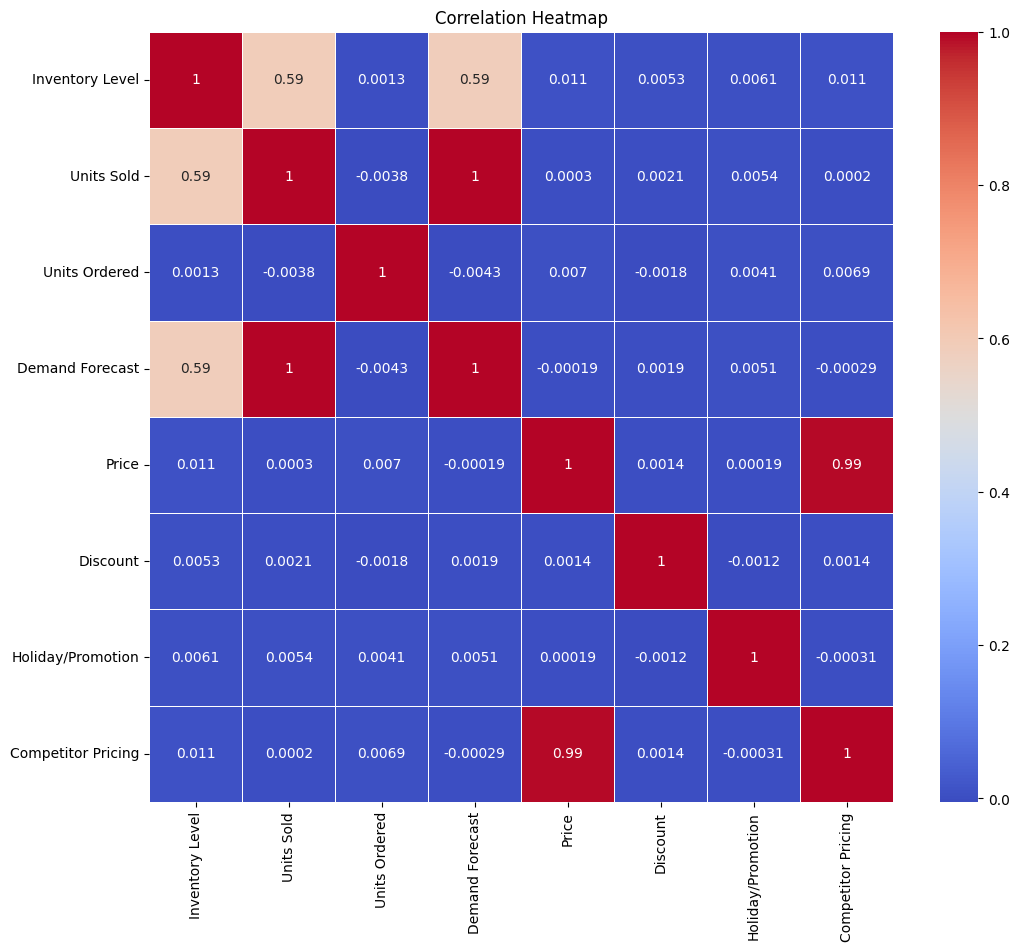

In [ ]:
numeric_columns = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()


# Challenge 1: Time Series Demand Forecasting

In [ ]:
df = df.sort_values('Date')
daily_sales = df.groupby('Date')['Units Sold'].sum().reset_index()
daily_sales.set_index('Date', inplace=True)

In [ ]:
# Feature engineering: add day of week and month
daily_sales['DayOfWeek'] = daily_sales.index.dayofweek
daily_sales['Month'] = daily_sales.index.month

In [ ]:
# Normalize the data
scaler = MinMaxScaler()
sales_scaled = scaler.fit_transform(daily_sales)

In [ ]:
# Create sequences with multiple features
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:(i + seq_length), :])
        y.append(data[i + seq_length, 0])  # Target is 'Units Sold'
    return np.array(X), np.array(y)

seq_length = 60  # Increased sequence length for better context
X, y = create_sequences(sales_scaled, seq_length)

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the LSTM model
model = Sequential([
    LSTM(100, activation='relu', return_sequences=True, input_shape=(seq_length, X.shape[2])),
    Dropout(0.2),
    LSTM(100, activation='relu'),
    Dropout(0.2),
    Dense(50, activation='relu'),
    Dense(1)  # Output layer for predicting Units Sold
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
# Compile the model with a custom learning rate
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mse')

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

# Make predictions on the test set
lstm_predictions = model.predict(X_test)

# Inverse transform the predictions and actual values correctly
# We need to create a full feature set for inverse transformation.
lstm_predictions_full = np.column_stack((lstm_predictions, np.zeros((lstm_predictions.shape[0], X.shape[2] - 1))))
y_test_full = np.column_stack((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], X.shape[2] - 1))))

lstm_predictions_inverse = scaler.inverse_transform(lstm_predictions_full)[:, 0]
y_test_actual_inverse = scaler.inverse_transform(y_test_full)[:, 0]

# Calculate RMSE and MAE for LSTM predictions
lstm_rmse = np.sqrt(mean_squared_error(y_test_actual_inverse, lstm_predictions_inverse))
lstm_mae = mean_absolute_error(y_test_actual_inverse, lstm_predictions_inverse)

print("LSTM RMSE:", lstm_rmse)
print("LSTM MAE:", lstm_mae)

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 346ms/step - loss: 0.3808 - val_loss: 0.1692
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - loss: 0.0437 - val_loss: 0.0263
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - loss: 0.0175 - val_loss: 0.0189
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - loss: 0.0123 - val_loss: 0.0202
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - loss: 0.0092 - val_loss: 0.0189
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - loss: 0.0095 - val_loss: 0.0199
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - loss: 0.0089 - val_loss: 0.0192
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.0092 - val_loss: 0.0194
Epoch 9/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 0.0100 - val_loss: 0.0194
Epoch 10/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.0088 - val_loss: 0.0200
Epoch 11/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.0092 - val_loss: 0.0198
Epoch 12/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/s

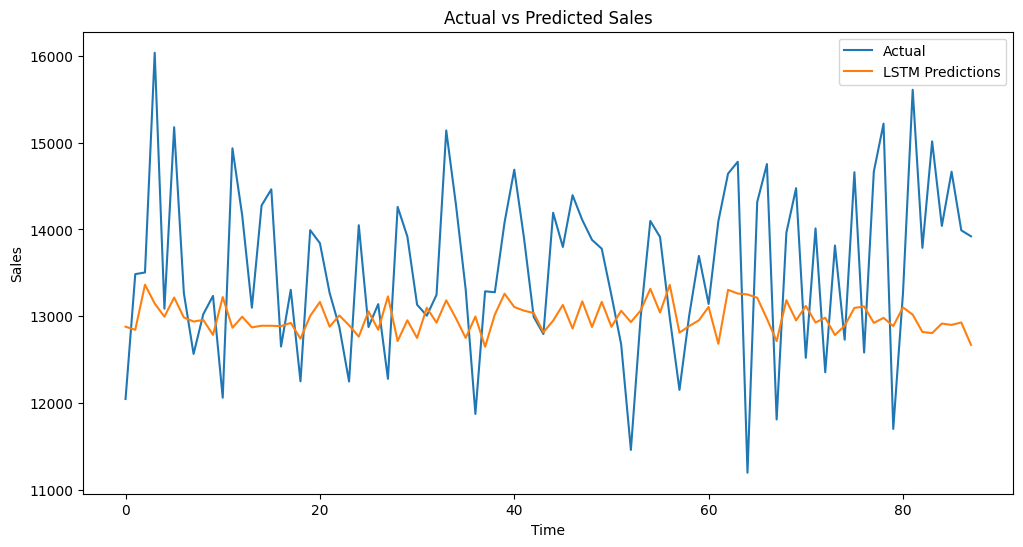

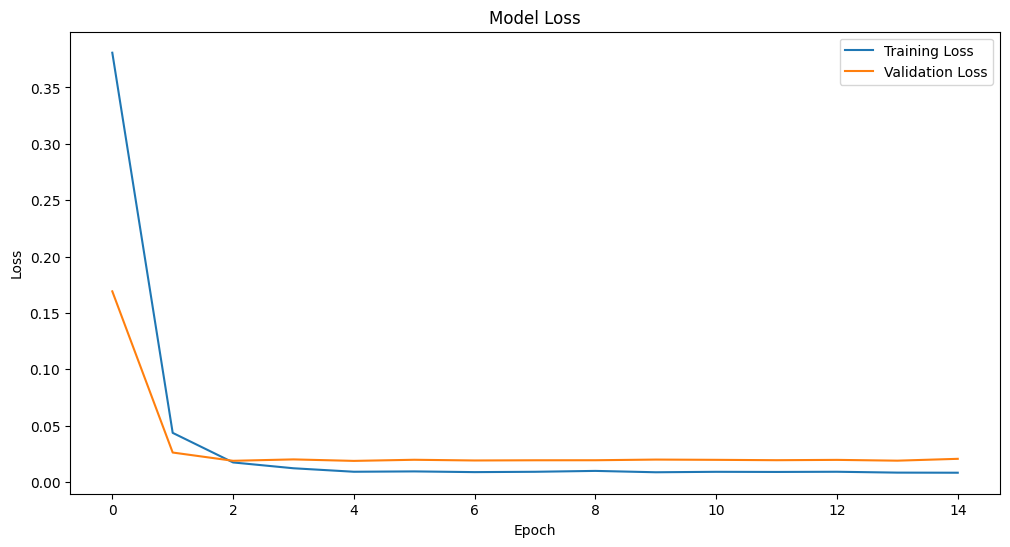

In [ ]:

# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(y_test_actual_inverse, label='Actual')
plt.plot(lstm_predictions_inverse, label='LSTM Predictions')
plt.title('Actual vs Predicted Sales')
plt.xlabel('Time')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Plot the training history to visualize loss over epochs
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

RMSE and MAE values around 911 and 729 respectively may indicate reasonable predictive accuracy
, continuous improvement through experimentation and validation is always beneficial.

# Challenge 2: Inventory Optimization

**To get result of demand forcasting challenge, start feature enginnering then model with random forest and XGBoost Separately and finally with Ensemble prediction methods I got better result that would be improve **

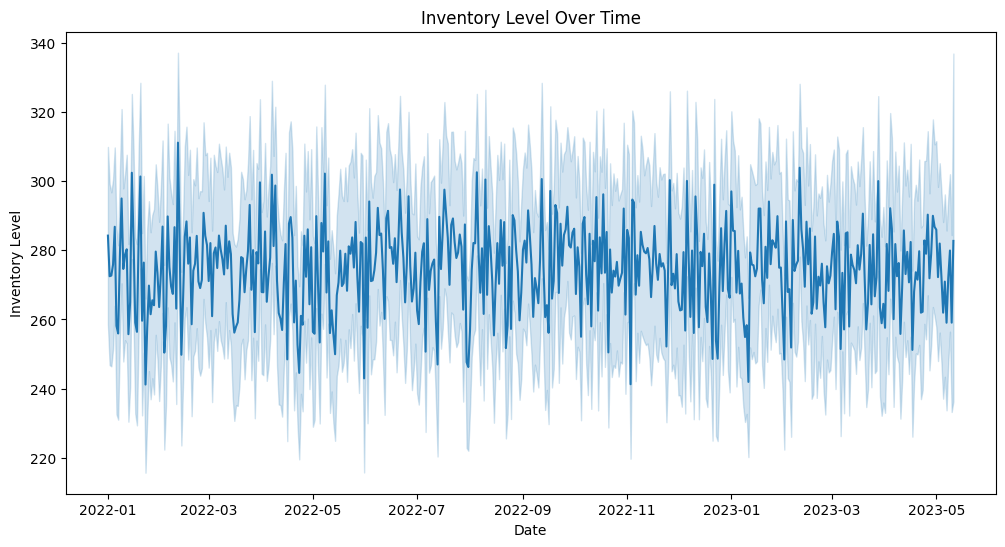

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='Inventory Level', data=df)
plt.title('Inventory Level Over Time')
plt.show()

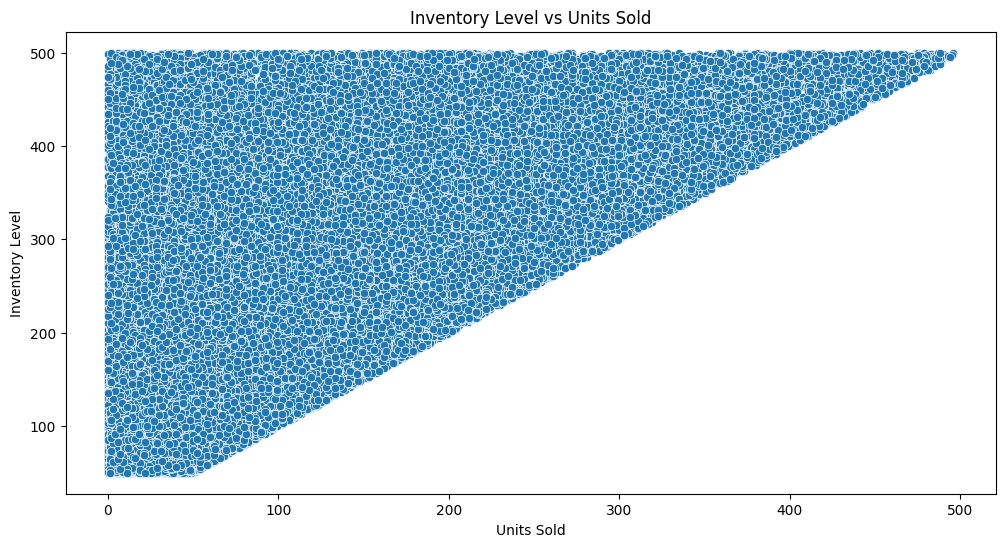

In [ ]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Units Sold', y='Inventory Level', data=df)
plt.title('Inventory Level vs Units Sold')
plt.show()

In [ ]:
# Calculate stockout frequency
stockout_freq = (df['Inventory Level'] == 0).mean()
print(f"Stockout frequency: {stockout_freq:.2%}")

Stockout frequency: 0.00%


In [ ]:
# Calculate overstock frequency
avg_daily_sales = df.groupby('Date')['Units Sold'].mean().mean()
overstock_freq = (df['Inventory Level'] > 2 * avg_daily_sales).mean()
print(f"Overstock frequency: {overstock_freq:.2%}")

Overstock frequency: 50.24%


In [ ]:
# Sort the DataFrame by date and store/product ID to ensure correct lag and rolling calculations
df = df.sort_values(['Store ID', 'Product ID', 'Date'])

# Create lag features
for lag in [1, 7]:
    df[f'Sales_Lag_{lag}'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(lag)

# Create rolling mean features
for window in [7, 14]:
    df[f'Sales_RollingMean_{window}'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].transform(lambda x: x.rolling(window=window, min_periods=1).mean())

# Add day of week and month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

# Handle missing values
df = df.dropna()

# Print the shape of the DataFrame before and after dropping NA values
print(f"Shape before dropping NA: {df.shape}")
print(f"Shape after dropping NA: {df.shape}")

# Check the created features
print(df[['Units Sold'] + [f'Sales_Lag_{lag}' for lag in [1, 7]] + [f'Sales_RollingMean_{window}' for window in [7, 14]] + ['DayOfWeek', 'Month']].head())

Shape before dropping NA: (48824, 21)
Shape after dropping NA: (48824, 21)
      Units Sold  Sales_Lag_1  Sales_Lag_7  Sales_RollingMean_7  \
700          2.0        107.0        127.0            62.428571   
800        350.0          2.0         81.0           100.857143   
900         36.0        350.0          5.0           105.285714   
1000        16.0         36.0         58.0            99.285714   
1100       104.0         16.0        147.0            93.142857   

      Sales_RollingMean_14  DayOfWeek  Month  
700              70.500000          5      1  
800             101.555556          6      1  
900              95.000000          0      1  
1000             87.818182          1      1  
1100             89.166667          2      1  


In [ ]:
# Prepare features and target
features = ['Sales_Lag_1', 'Sales_Lag_7', 'Sales_RollingMean_7', 'DayOfWeek', 'Month', 'Price', 'Discount']
X = df[features]
y = df['Units Sold']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")

Mean Squared Error: 10408.21


Mean Absolute Error: 82.36
R-squared Score: 0.13


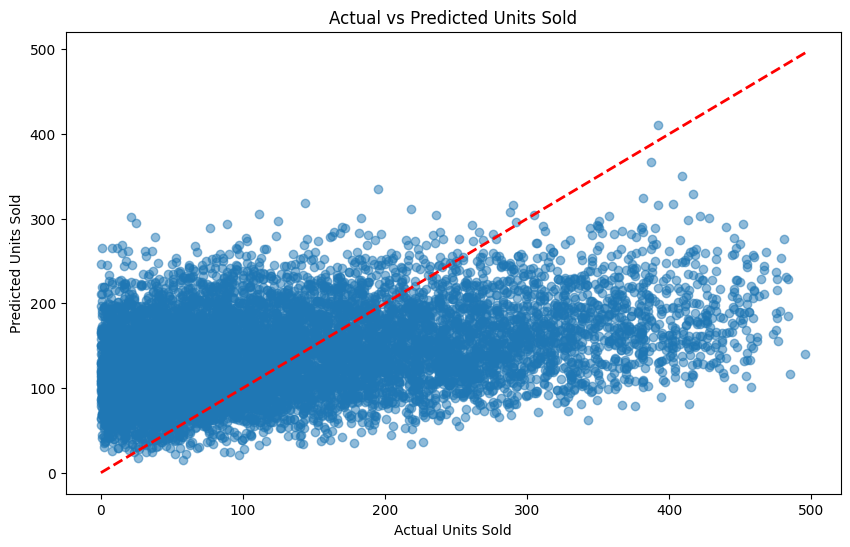

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Calculate additional metrics
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {mae:.2f}")
print(f"R-squared Score: {r2:.2f}")

# Visualize predictions vs actual
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.title("Actual vs Predicted Units Sold")
plt.show()



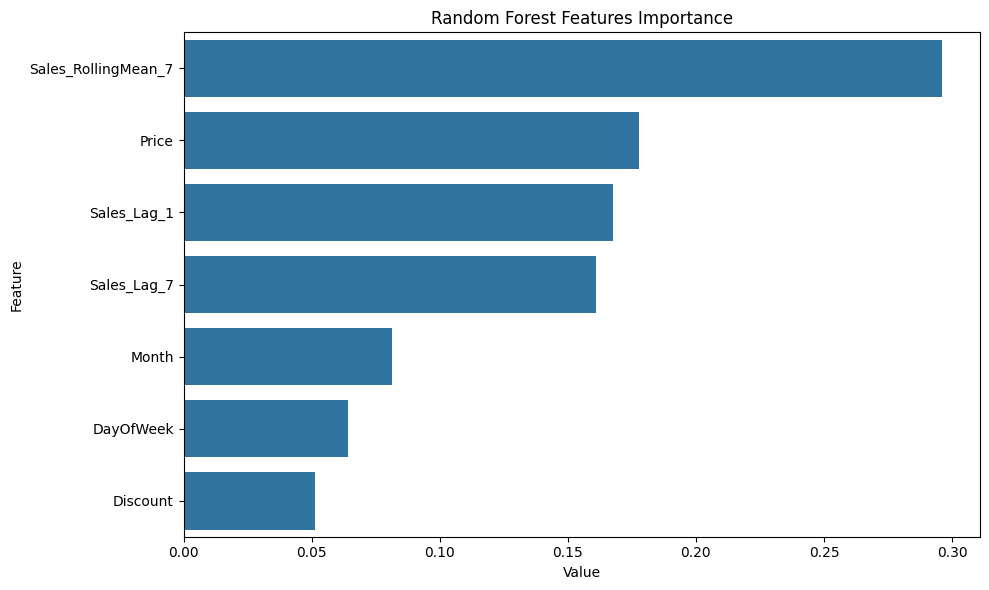

In [ ]:
# Feature importance
importances = rf_model.feature_importances_
feature_imp = pd.DataFrame(sorted(zip(importances, features)), columns=['Value','Feature'])

plt.figure(figsize=(10, 6))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
plt.title('Random Forest Features Importance')
plt.tight_layout()
plt.show()

Feature dicscount Dayof week are less important

In [ ]:
# Prepare features and target
features = ['Sales_Lag_1', 'Sales_Lag_7', 'Sales_RollingMean_7', 'DayOfWeek', 'Month', 'Price', 'Discount']
X = df[features]
y = df['Units Sold']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train xgb boost
xgb_model = XGBRegressor(random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("\nXGBoost Results:")
print(f"MSE: {mean_squared_error(y_test, y_pred_xgb):.2f}")
print(f"R-squared: {r2_score(y_test, y_pred_xgb):.2f}")


XGBoost Results:
MSE: 10566.49
R-squared: 0.11


In [ ]:

# Prepare the data again
X = df[features]
y = df['Units Sold']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [ ]:
# Create and fit the ensemble
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_model = XGBRegressor(random_state=42)
lr_model = LinearRegression()

In [ ]:
ensemble = VotingRegressor(
    estimators=[('rf', rf_model), ('xgb', xgb_model), ('lr', lr_model)],
    weights=[2, 2, 1]
)

In [ ]:

ensemble.fit(X_train, y_train)

# Make predictions
y_pred_ensemble = ensemble.predict(X_test)

In [ ]:
# Evaluate the ensemble model
mse_ensemble = mean_squared_error(y_test, y_pred_ensemble)
r2_ensemble = r2_score(y_test, y_pred_ensemble)

print("Ensemble Model Results (original features):")
print(f"MSE: {mse_ensemble:.2f}")
print(f"R-squared: {r2_ensemble:.2f}")

Ensemble Model Results (original features):
MSE: 10147.89
R-squared: 0.15



* ****MSE (Mean Squared Error):
*
*
* Previous XGBoost model: 10361.02
*
*
* New Ensemble model: 10095.35
*
*
* This represents a decrease in MSE of about 2.6%, which is a modest improvement.
*
*
* R-squared:Previous models: 0.12
*
* New Ensemble model: 0.14

vement,

# Challenge 3: Dynamic Pricing
.

In [ ]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality', 'Sales_Lag_1', 'Sales_Lag_7',
       'Sales_RollingMean_7', 'Sales_RollingMean_14', 'DayOfWeek', 'Month'],
      dtype='object')

In [ ]:

# Encode categorical variables
le = LabelEncoder()
categorical_features = ['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Holiday/Promotion','Seasonality']
for feature in categorical_features:
    df[feature] = le.fit_transform(df[feature])




In [ ]:
# Define features for the pricing model
pricing_features = ['Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level',
                    'Demand Forecast', 'Competitor Pricing', 'Seasonality',
                    'Sales_Lag_1', 'Sales_Lag_7', 'Sales_RollingMean_7',
                    'Sales_RollingMean_14', 'DayOfWeek', 'Month'
                    , 'Weather Condition', 'Holiday/Promotion']


In [ ]:
X = df[pricing_features]
y = df['Price']


In [ ]:
X.head()

,Store ID,Product ID,Category,Region,Inventory Level,Demand Forecast,Competitor Pricing,Seasonality,Sales_Lag_1,Sales_Lag_7,Sales_RollingMean_7,Sales_RollingMean_14,DayOfWeek,Month,Weather Condition,Holiday/Promotion
700,0,0,2,0,231.0,0.84,63.82,3,107.0,127.0,62.428571,70.500000,5,1,0,1
800,0,0,1,2,373.0,352.24,38.68,2,2.0,81.0,100.857143,101.555556,6,1,3,1
900,0,0,1,3,327.0,39.50,34.71,2,350.0,5.0,105.285714,95.000000,0,1,2,1
1000,0,0,2,3,101.0,16.11,27.08,0,36.0,58.0,99.285714,87.818182,1,1,1,1
1100,0,0,4,2,145.0,100.32,97.59,3,16.0,147.0,93.142857,89.166667,2,1,2,0


In [ ]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [ ]:
# Train the XGBoost model
modelxgb =XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
modelxgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred = modelxgb.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")

Mean Squared Error: 8.00
R-squared Score: 0.99
